# Logistic Regression, Step by Step
One small example all the way through: **10 students**, the **hours studied per day**, and whether they **passed (1) or failed (0)**.

Steps we will follow (same as the notes and the interactive page):
1. Data
2. Why a straight line is not enough
3. Sigmoid and the hypothesis
4. Cost function: try many theta values and draw the curve
5. Why not mean squared error, why log loss
6. Gradient descent finds the best theta
7. Why it is called "linear"
8. Assumptions
9. Same thing with scikit-learn

## 1. Data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1,2,3,4,5,6,7,8,9,10])   # hours studied per day
y = np.array([0,0,0,0,1,0,1,1,1,1])    # 1 = passed, 0 = failed
print("x:", x)
print("y:", y)

x: [ 1  2  3  4  5  6  7  8  9 10]
y: [0 0 0 0 1 0 1 1 1 1]


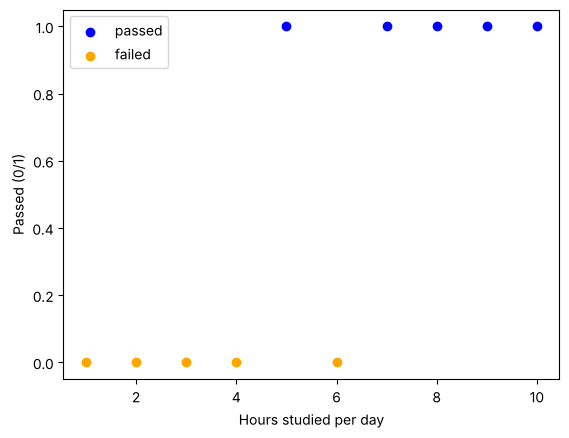

In [2]:
plt.scatter(x[y==1], y[y==1], color='blue', label='passed')
plt.scatter(x[y==0], y[y==0], color='orange', label='failed')
plt.xlabel("Hours studied per day"); plt.ylabel("Passed (0/1)")
plt.legend(); plt.show()

## 2. Why a straight line is not enough
First try the obvious idea: fit a straight line (linear regression) to the 0s and 1s.

In [3]:
slope, intercept = np.polyfit(x, y, 1)
print(f"line: y = {intercept:.3f} + {slope:.3f} x")

for h in [0, 2, 5, 8, 10, 12]:
    v = intercept + slope*h
    print(f"hours = {h:2d}  line value = {v:6.2f}  as a chance = {v*100:5.0f}%")

line: y = -0.267 + 0.139 x
hours =  0  line value =  -0.27  as a chance =   -27%
hours =  2  line value =   0.01  as a chance =     1%
hours =  5  line value =   0.43  as a chance =    43%
hours =  8  line value =   0.85  as a chance =    85%
hours = 10  line value =   1.13  as a chance =   113%
hours = 12  line value =   1.41  as a chance =   141%


**Problem 1:** the line values are not real probabilities, the line was only fitted to be close to 0s and 1s.

**Problem 2:** at 0 hours the line says -0.27 and at 12 hours it says 1.41. A chance of -27% or 141% is impossible.

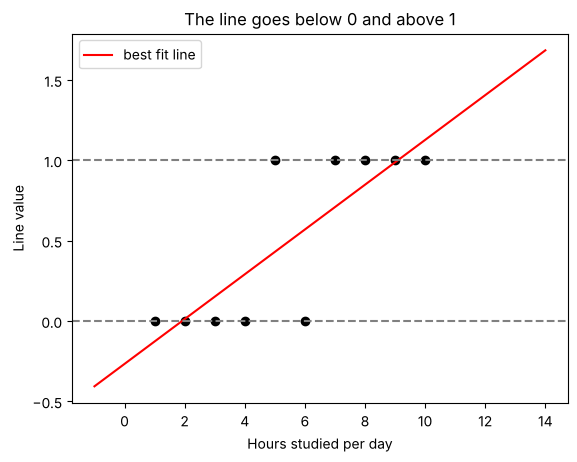

In [4]:
hh = np.linspace(-1, 14, 100)
plt.plot(hh, intercept + slope*hh, color='red', label='best fit line')
plt.scatter(x, y, color='black')
plt.axhline(0, color='gray', linestyle='--'); plt.axhline(1, color='gray', linestyle='--')
plt.xlabel("Hours studied per day"); plt.ylabel("Line value")
plt.title("The line goes below 0 and above 1"); plt.legend(); plt.show()

**Problem 3: outliers.** Add one extreme student who studied 20 hours per day (below 24) and passed. The line moves even though that student is correct.

In [5]:
x2 = np.append(x, 20); y2 = np.append(y, 1)
s2, i2 = np.polyfit(x2, y2, 1)
print("boundary (line = 0.5) before:", round((0.5-intercept)/slope, 2), "hours")
print("boundary (line = 0.5) after :", round((0.5-i2)/s2, 2), "hours")

boundary (line = 0.5) before: 5.5 hours
boundary (line = 0.5) after : 6.13 hours


## 3. Sigmoid and the hypothesis
Keep the linear part `z = theta0 + theta1 * x`, then squash it into 0 to 1:

`g(z) = 1 / (1 + e^-z)`

In [6]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

for z in [-6, -2, 0, 2, 6]:
    print(f"z = {z:2d}  g(z) = {sigmoid(z):.4f}")

z = -6  g(z) = 0.0025
z = -2  g(z) = 0.1192
z =  0  g(z) = 0.5000
z =  2  g(z) = 0.8808
z =  6  g(z) = 0.9975


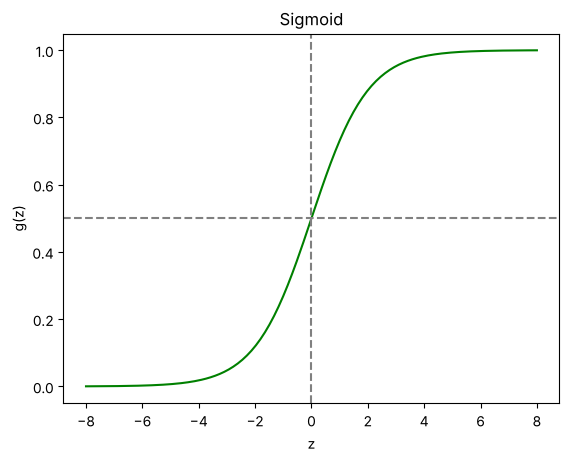

In [7]:
z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z), color='green')
plt.axhline(0.5, color='gray', linestyle='--'); plt.axvline(0, color='gray', linestyle='--')
plt.xlabel("z"); plt.ylabel("g(z)"); plt.title("Sigmoid"); plt.show()

Hypothesis: `h(x) = g(theta0 + theta1 * x)` is the **probability of passing**. Predict 1 when it is at least 0.5, which means `z >= 0`. The decision boundary is `x = -theta0 / theta1`.

Try some theta values by hand:

In [8]:
def predict_prob(theta0, theta1, x):
    return sigmoid(theta0 + theta1*x)

theta0, theta1 = -7.15, 1.3
p = predict_prob(theta0, theta1, x)
for h, pi, yi in zip(x, p, y):
    pred = int(pi >= 0.5)
    print(f"hours={h:2d}  prob={pi:.3f}  predicted={pred}  actual={yi}  {'right' if pred==yi else 'WRONG'}")
print("boundary:", round(-theta0/theta1, 2), "hours")

hours= 1  prob=0.003  predicted=0  actual=0  right
hours= 2  prob=0.010  predicted=0  actual=0  right
hours= 3  prob=0.037  predicted=0  actual=0  right
hours= 4  prob=0.125  predicted=0  actual=0  right
hours= 5  prob=0.343  predicted=0  actual=1  WRONG
hours= 6  prob=0.657  predicted=1  actual=0  WRONG
hours= 7  prob=0.875  predicted=1  actual=1  right
hours= 8  prob=0.963  predicted=1  actual=1  right
hours= 9  prob=0.990  predicted=1  actual=1  right
hours=10  prob=0.997  predicted=1  actual=1  right
boundary: 5.5 hours


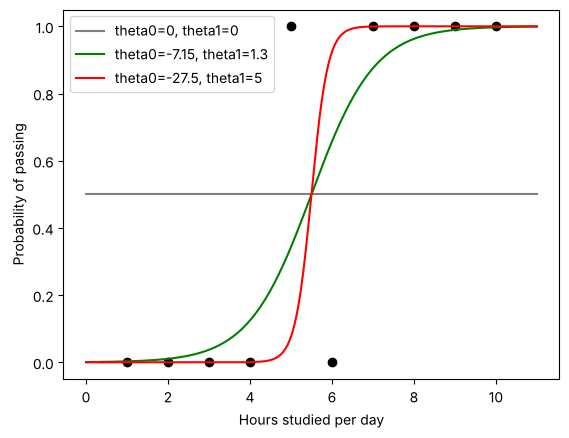

In [9]:
hh = np.linspace(0, 11, 200)
for t0, t1, c in [(0, 0, 'gray'), (-7.15, 1.3, 'green'), (-27.5, 5, 'red')]:
    plt.plot(hh, predict_prob(t0, t1, hh), color=c, label=f"theta0={t0}, theta1={t1}")
plt.scatter(x, y, color='black')
plt.xlabel("Hours studied per day"); plt.ylabel("Probability of passing")
plt.legend(); plt.show()

## 4. Cost function: try many theta values and draw the curve
Same idea as the `y = 2x` warm-up: try many theta values, compute the cost for each, plot cost against theta. The lowest point of the bowl is the best theta.

Warm-up first (points (1,2), (2,4), (3,6), model `y = theta * x`):

Theta: 0, Loss: 9.33
Theta: 1, Loss: 2.33
Theta: 2, Loss: 0.00
Theta: 3, Loss: 2.33
Theta: 4, Loss: 9.33


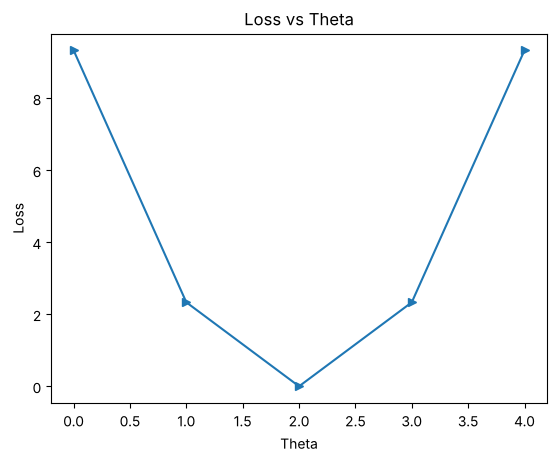

In [10]:
wx = np.array([1,2,3]); wy = np.array([2,4,6])
thetas = [0, 1, 2, 3, 4]
wj = []
for t in thetas:
    y_pred = t*wx
    loss = 1/(2*len(wx)) * np.sum((y_pred - wy)**2)
    wj.append(loss)
    print(f"Theta: {t}, Loss: {loss:.2f}")
plt.plot(thetas, wj, marker='>'); plt.xlabel("Theta"); plt.ylabel("Loss"); plt.title("Loss vs Theta"); plt.show()

Theta 1 is too small (high cost), theta 2 is perfect (cost 0), theta 3 is too big (high cost). The best theta is the bottom of the bowl.

Now the same for logistic regression. To change only one number, fix theta0 at the best value we assume, **-7.15**, and try different slopes `theta1`. The cost here is **log loss**, explained in section 5. For now just see the bowl.

In [11]:
def log_loss(theta0, theta1):
    p = predict_prob(theta0, theta1, x)
    p = np.clip(p, 1e-12, 1-1e-12)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

slopes = [0, 0.25, 0.5, 1, 1.3, 2, 3, 5]
for t1 in slopes:
    print(f"theta1 = {t1:4}  cost = {log_loss(-7.15, t1):.3f}")

theta1 =    0  cost = 3.576
theta1 = 0.25  cost = 2.604
theta1 =  0.5  cost = 1.653
theta1 =    1  cost = 0.393
theta1 =  1.3  cost = 0.251
theta1 =    2  cost = 0.644
theta1 =    3  cost = 1.799
theta1 =    5  cost = 4.657


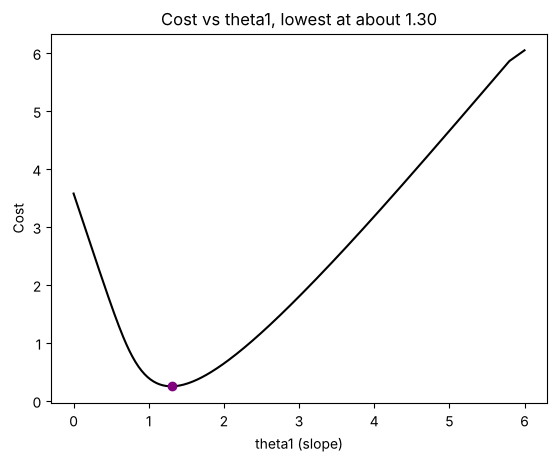

In [12]:
grid = np.linspace(0, 6, 300)
costs = [log_loss(-7.15, t) for t in grid]
plt.plot(grid, costs, color='black')
best = grid[np.argmin(costs)]
plt.scatter(best, min(costs), color='purple', zorder=5)
plt.xlabel("theta1 (slope)"); plt.ylabel("Cost"); plt.title(f"Cost vs theta1, lowest at about {best:.2f}")
plt.show()

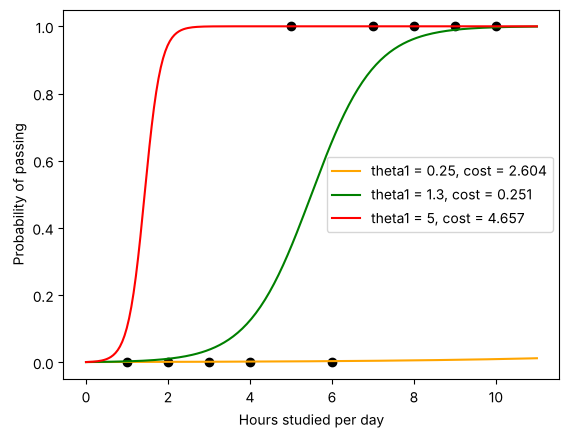

In [13]:
hh = np.linspace(0, 11, 200)
for t1, c in [(0.25, 'orange'), (1.3, 'green'), (5, 'red')]:
    plt.plot(hh, sigmoid(-7.15 + t1*hh), color=c, label=f"theta1 = {t1}, cost = {log_loss(-7.15, t1):.3f}")
plt.scatter(x, y, color='black'); plt.legend()
plt.xlabel("Hours studied per day"); plt.ylabel("Probability of passing"); plt.show()

A small theta1 never reaches 50% (predicts fail for everyone), so the passers are badly wrong. A big theta1 reaches 50% after about 1.4 hours (predicts pass for almost everyone), so the failers are badly wrong. The cost is lowest in between.

## 5. Why not mean squared error, why log loss
### Two-coin example
Coin 1: you predict 0.2, real 0.1. Coin 2: you predict 0.6, real 0.3. Both predictions are twice the truth.

In [14]:
for pred, real in [(0.2, 0.1), (0.6, 0.3)]:
    print(f"pred={pred} real={real}  squared error={(pred-real)**2:.4f}  ln(pred/real)={np.log(pred/real):.3f}")

pred=0.2 real=0.1  squared error=0.0100  ln(pred/real)=0.693
pred=0.6 real=0.3  squared error=0.0900  ln(pred/real)=0.693


Squared error says coin 2 is 9 times worse. The log ratio says both are equally wrong (0.693). Log loss works on this log scale.

### Log loss for one student
`loss = -log(p)` if the student passed, and `-log(1-p)` if the student failed.
One formula: `-( y*log(p) + (1-y)*log(1-p) )`

In [15]:
for actual, p in [(1,0.9),(1,0.5),(1,0.1),(1,0.01),(0,0.1),(0,0.9)]:
    loss = -(actual*np.log(p) + (1-actual)*np.log(1-p))
    print(f"actual={actual}  predicted={p:.2f}  loss={loss:.3f}")

actual=1  predicted=0.90  loss=0.105
actual=1  predicted=0.50  loss=0.693
actual=1  predicted=0.10  loss=2.303
actual=1  predicted=0.01  loss=4.605
actual=0  predicted=0.10  loss=0.105
actual=0  predicted=0.90  loss=2.303


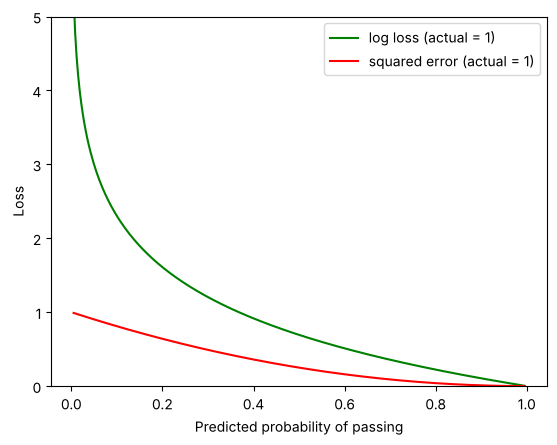

In [16]:
p = np.linspace(0.005, 0.995, 300)
plt.plot(p, -np.log(p), color='green', label='log loss (actual = 1)')
plt.plot(p, (p-1)**2, color='red', label='squared error (actual = 1)')
plt.ylim(0, 5); plt.xlabel("Predicted probability of passing"); plt.ylabel("Loss")
plt.legend(); plt.show()

A confident wrong answer costs a lot more with log loss (it grows without limit). Now compare the two costs on the sigmoid output, changing only `theta1` with `theta0` fixed at -7.15:

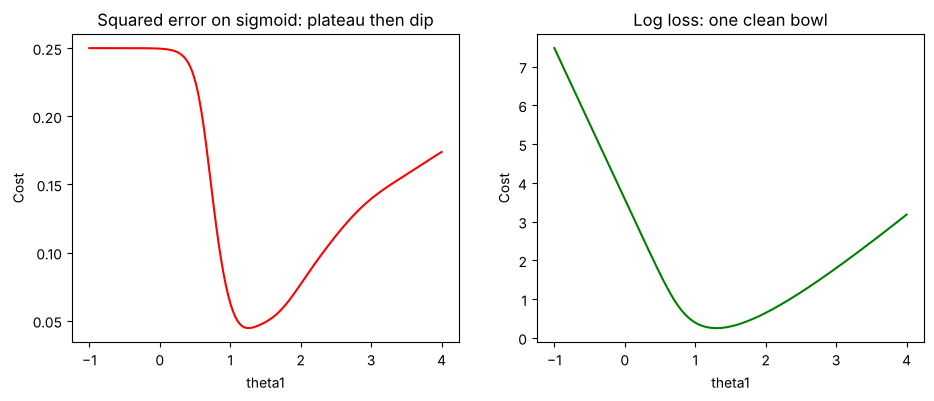

In [17]:
def mse_sig(theta0, theta1):
    p = predict_prob(theta0, theta1, x)
    return np.sum((p - y)**2) / (2*len(x))

grid = np.linspace(-1, 4, 300)
mse_c = [mse_sig(-7.15, t) for t in grid]
ll_c  = [log_loss(-7.15, t) for t in grid]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grid, mse_c, color='red');   ax[0].set_title("Squared error on sigmoid: plateau then dip")
ax[1].plot(grid, ll_c, color='green');  ax[1].set_title("Log loss: one clean bowl")
for a in ax: a.set_xlabel("theta1"); a.set_ylabel("Cost")
plt.show()

The flat part of the squared-error curve has almost zero slope, so gradient descent barely moves there. Log loss is a clean bowl.

## 6. Gradient descent finds the best theta
Steps: start theta0 = 0, theta1 = 0, then repeat:
1. `z = theta0 + theta1*x`, `p = sigmoid(z)`
2. error `= p - y`
3. gradients: `d0 = mean(error)`, `d1 = mean(error * x)`
4. update: `theta = theta - alpha * gradient`

First update by hand (alpha = 0.1):

In [18]:
t0, t1, alpha = 0.0, 0.0, 0.1
p = sigmoid(t0 + t1*x)
error = p - y
print("errors:", error)
d0 = np.mean(error); d1 = np.mean(error*x)
print("d0 =", d0, " d1 =", d1)
print("new theta0 =", t0 - alpha*d0, " new theta1 =", t1 - alpha*d1)

errors: [ 0.5  0.5  0.5  0.5 -0.5  0.5 -0.5 -0.5 -0.5 -0.5]
d0 = 0.0  d1 = -1.15
new theta0 = 0.0  new theta1 = 0.11499999999999999


Now repeat it many times and record the cost each time.

In [19]:
def gradient_descent(alpha, steps):
    t0, t1 = 0.0, 0.0
    hist = [(t0, t1, log_loss(t0, t1))]
    for k in range(steps):
        error = sigmoid(t0 + t1*x) - y
        t0 -= alpha*np.mean(error)
        t1 -= alpha*np.mean(error*x)
        hist.append((t0, t1, log_loss(t0, t1)))
    return np.array(hist)

h = gradient_descent(0.1, 30000)
for k in [0, 1, 2, 3, 10, 100, 1000, 5000, 30000]:
    print(f"iteration {k:5d}  theta0 = {h[k,0]:7.3f}  theta1 = {h[k,1]:6.3f}  cost = {h[k,2]:.3f}")

iteration     0  theta0 =   0.000  theta1 =  0.000  cost = 0.693
iteration     1  theta0 =   0.000  theta1 =  0.115  cost = 0.622
iteration     2  theta0 =  -0.015  theta1 =  0.127  cost = 0.619
iteration     3  theta0 =  -0.031  theta1 =  0.131  cost = 0.616
iteration    10  theta0 =  -0.142  theta1 =  0.148  cost = 0.598
iteration   100  theta0 =  -1.285  theta1 =  0.325  cost = 0.448
iteration  1000  theta0 =  -4.768  theta1 =  0.895  cost = 0.268
iteration  5000  theta0 =  -6.859  theta1 =  1.250  cost = 0.251
iteration 30000  theta0 =  -7.159  theta1 =  1.302  cost = 0.251


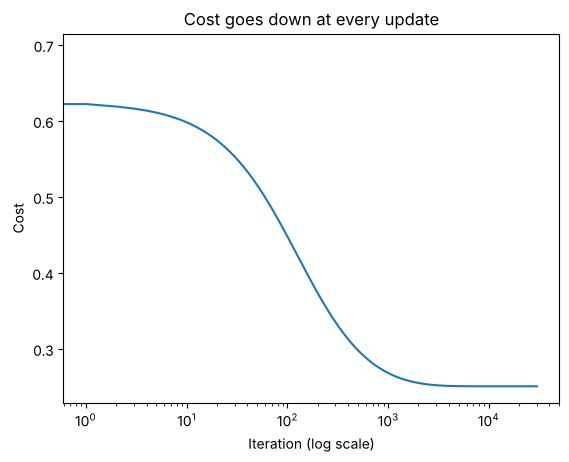

In [20]:
plt.plot(h[:,2]); plt.xscale('log')
plt.xlabel("Iteration (log scale)"); plt.ylabel("Cost"); plt.title("Cost goes down at every update")
plt.show()

best theta0 = -7.159, theta1 = 1.302
decision boundary: 5.5 hours per day
7-hour student passes with probability: 0.88


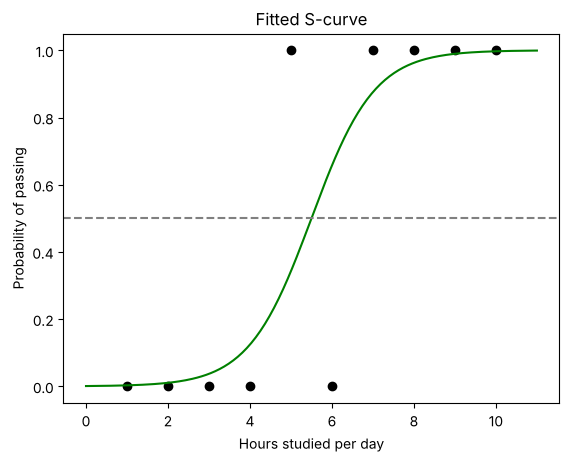

In [21]:
t0, t1 = h[-1,0], h[-1,1]
print(f"best theta0 = {t0:.3f}, theta1 = {t1:.3f}")
print("decision boundary:", round(-t0/t1, 2), "hours per day")
print("7-hour student passes with probability:", round(sigmoid(t0 + t1*7), 2))

hh = np.linspace(0, 11, 200)
plt.plot(hh, sigmoid(t0 + t1*hh), color='green')
plt.scatter(x, y, color='black'); plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel("Hours studied per day"); plt.ylabel("Probability of passing"); plt.title("Fitted S-curve"); plt.show()

**Learning rate.** Try a few values and compare. Too small is slow, too large overshoots.

In [22]:
for a in [0.01, 0.1, 0.3]:
    hh_ = gradient_descent(a, 3000)
    print(f"alpha = {a:4}  cost after 1 update = {hh_[1,2]:.3f}  after 3000 updates = {hh_[-1,2]:.3f}")

alpha = 0.01  cost after 1 update = 0.681  after 3000 updates = 0.336
alpha =  0.1  cost after 1 update = 0.622  after 3000 updates = 0.252


alpha =  0.3  cost after 1 update = 0.750  after 3000 updates = 0.251


## 7. Why is it called "linear"?
The **log-odds** are a straight line in the features:

`log( p / (1-p) ) = theta0 + theta1 * x`

In [23]:
p = sigmoid(t0 + t1*x)
log_odds = np.log(p/(1-p))
print("log-odds from probabilities:", np.round(log_odds, 2))
print("theta0 + theta1 * x        :", np.round(t0 + t1*x, 2))
print("odds multiply by", round(np.exp(t1), 2), "for each extra hour of study per day")

log-odds from probabilities: [-5.86 -4.56 -3.25 -1.95 -0.65  0.65  1.95  3.25  4.56  5.86]
theta0 + theta1 * x        : [-5.86 -4.56 -3.25 -1.95 -0.65  0.65  1.95  3.25  4.56  5.86]
odds multiply by 3.68 for each extra hour of study per day


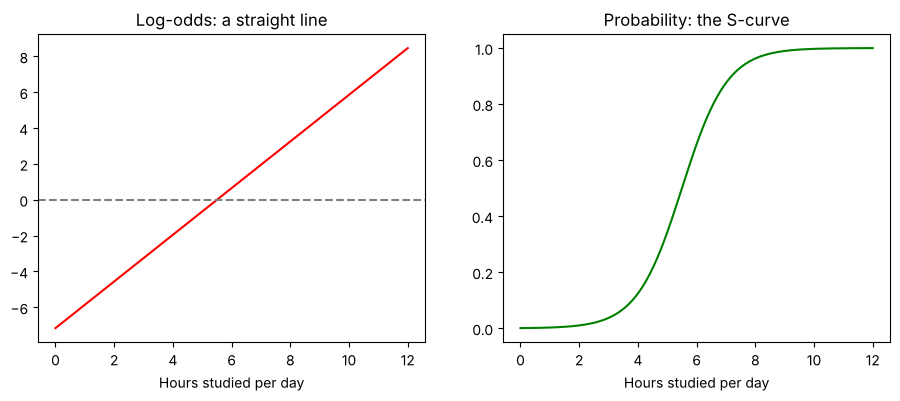

In [24]:
hh = np.linspace(0, 12, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hh, t0 + t1*hh, color='red');           ax[0].set_title("Log-odds: a straight line");  ax[0].axhline(0, color='gray', linestyle='--')
ax[1].plot(hh, sigmoid(t0 + t1*hh), color='green'); ax[1].set_title("Probability: the S-curve")
for a in ax: a.set_xlabel("Hours studied per day")
plt.show()

The decision boundary `z = 0` is also a straight line (a single point with one feature, a line with two features).

## 8. Assumptions
1. Independent observations
2. Binary target
3. Linear relationship between features and the **log-odds**
4. No extreme outliers
5. Large enough sample
6. No strong multicollinearity

Not needed (unlike linear regression): normal residuals and constant variance of errors.

**Check 6, multicollinearity:** make x2 almost a copy of x1 and fit on two halves of the data.

In [25]:
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(7)
n = 80
x1 = rng.uniform(1, 9, n)
x2 = x1 + 0.15*(rng.random(n) - 0.5)*2          # almost the same as x1
yy = (rng.random(n) < sigmoid(-4.5 + 0.9*x1)).astype(int)
F = np.column_stack([x1, x2])

for name, sl in [("first 40 ", slice(0,40)), ("second 40", slice(40,80))]:
    m = LogisticRegression(C=1e6, max_iter=5000).fit(F[sl], yy[sl])
    print(name, "coef x1 = %.2f  coef x2 = %.2f  sum = %.2f" % (m.coef_[0,0], m.coef_[0,1], m.coef_.sum()))

first 40  coef x1 = -0.71  coef x2 = 1.65  sum = 0.94
second 40 coef x1 = 2.68  coef x2 = -1.24  sum = 1.44


The two coefficients jump around between halves, and even change sign, while their **sum** stays in a narrower range. The two features share one signal, so the model cannot split the credit. Drop or combine such features.

## 9. Same thing with scikit-learn
`fit` does the gradient descent (or a similar solver) for us.

In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(C=1e6)     # large C = almost no regularization
model.fit(x.reshape(-1,1), y)
print("theta0 (intercept):", model.intercept_[0])
print("theta1 (coef)     :", model.coef_[0,0])
print("boundary          :", -model.intercept_[0]/model.coef_[0,0], "hours")

theta0 (intercept): -7.158637402582915
theta1 (coef)     : 1.301543372649511
boundary          : 5.500114366538782 hours


In [27]:
new = np.array([[7], [6.5], [3]])
print("probability of [fail, pass]:\n", model.predict_proba(new))
print("predicted class:", model.predict(new))

probability of [fail, pass]:
 [[0.12431735 0.87568265]
 [0.21393042 0.78606958]
 [0.96281684 0.03718316]]
predicted class: [1 1 0]


These match our hand-built gradient descent (theta0 about -7.16, theta1 about 1.30).

## Recap
| Question | Short answer |
|---|---|
| Why not a straight line? | Values below 0 and above 1, not real chances, outliers shift it |
| Why sigmoid? | Squashes any score into 0 to 1, so it is a probability |
| Why not squared error? | Not a bowl on the sigmoid output, log loss is |
| Why log? | Equal mistakes by the same factor cost the same, confident wrong answers cost a lot |
| How is theta found? | Gradient descent: `theta = theta - alpha * mean((p - y) * x)` |
| Why linear? | Log-odds are a straight line in the features |